<a href="https://colab.research.google.com/github/kirshtalreja24/retinal-cgan-dr/blob/main/notebooks/04_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q "torchmetrics[image]"

import os, copy, time, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, recall_score, confusion_matrix

PROJECT = '/content/drive/MyDrive/GenAI_Project'
RES = f'{PROJECT}/results'
os.makedirs(RES, exist_ok=True); os.makedirs(f'{PROJECT}/checkpoints', exist_ok=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

d = np.load(f'{PROJECT}/dataset/aptos_64.npz')
split, IMAGES, LABELS = d['split'], d['images'], d['labels']
Xtr, Ytr = IMAGES[split == 'train'], LABELS[split == 'train']
Xva, Yva = IMAGES[split == 'val'], LABELS[split == 'val']
Xte, Yte = IMAGES[split == 'test'], LABELS[split == 'test']
NUM_CLASSES, MINORITY = 3, 2                      # label 2 = grade 4
CLASS_NAMES = ['Grade 0', 'Grade 2', 'Grade 4']
SYN = {m: {s: dict(np.load(f'{PROJECT}/synthetic/{m}_seed{s}.npz')) for s in range(3)}
       for m in ['cgan', 'cvae']}

for name, y in [('train', Ytr), ('val', Yva), ('test', Yte)]:
    print(f'{name:5s}', np.bincount(y, minlength=3))
print('synthetic cGAN seed0:', SYN['cgan'][0]['images'].shape, ' cVAE seed0:', SYN['cvae'][0]['images'].shape)
corner = SYN['cgan'][0]['images'][:, :3, :3].max()
print('cGAN corner max (must be 0):', corner)

Mounted at /content/drive
device: cuda
train [1263  699  207]
val   [262 120  39]
test  [264 127  41]
synthetic cGAN seed0: (3000, 64, 64, 3)  cVAE seed0: (3000, 64, 64, 3)
cGAN corner max (must be 0): 0


In [3]:
EPOCHS, BATCH, LR, WD, INPUT = 30, 64, 3e-4, 1e-4, 128
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
USE_AMP = device == 'cuda'

class Classifier(nn.Module):
    """ResNet-18 (ImageNet init). Identical in every experiment.
    64px input is resized to 128px INSIDE the model, so real and synthetic
    images always take exactly the same path."""
    def __init__(self):
        super().__init__()
        self.net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        self.net.fc = nn.Linear(self.net.fc.in_features, NUM_CLASSES)
    def forward(self, x):                                  # x in [0, 1]
        x = F.interpolate(x, size=INPUT, mode='bilinear', align_corners=False)
        return self.net((x - MEAN) / STD)

def gpu_aug(x):
    """Classical augmentation (E2, E6): flips, rotation +-15 deg, brightness/contrast +-20%."""
    B = x.size(0)
    x = torch.where(torch.rand(B, 1, 1, 1, device=x.device) < 0.5, x.flip(3), x)
    x = torch.where(torch.rand(B, 1, 1, 1, device=x.device) < 0.5, x.flip(2), x)
    ang = (torch.rand(B, device=x.device) * 2 - 1) * (15 * np.pi / 180)
    cos, sin, zero = ang.cos(), ang.sin(), torch.zeros_like(ang)
    theta = torch.stack([torch.stack([cos, -sin, zero], 1), torch.stack([sin, cos, zero], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, list(x.shape), align_corners=False), align_corners=False)
    x = x * (1 + (torch.rand(B, 1, 1, 1, device=x.device) * 2 - 1) * 0.2)          # brightness
    m = x.mean(dim=[1, 2, 3], keepdim=True)
    x = (x - m) * (1 + (torch.rand(B, 1, 1, 1, device=x.device) * 2 - 1) * 0.2) + m  # contrast
    return x.clamp(0, 1)

def to_tensor(x_uint8):
    return torch.from_numpy(x_uint8).to(device).permute(0, 3, 1, 2).float() / 255

@torch.no_grad()
def predict(model, x):
    model.eval(); out = []
    for s in range(0, len(x), 256):
        with torch.autocast(device, enabled=USE_AMP):
            out.append(model(to_tensor(x[s:s + 256])).argmax(1).cpu())
    return torch.cat(out).numpy()

def metrics(y, p):
    L = list(range(NUM_CLASSES))
    r = recall_score(y, p, labels=L, average=None, zero_division=0)
    return {'accuracy': accuracy_score(y, p),
            'macro_f1': f1_score(y, p, labels=L, average='macro', zero_division=0),
            'qwk': cohen_kappa_score(y, p, labels=L, weights='quadratic'),
            'recall_g0': r[0], 'recall_g2': r[1], 'recall_g4': r[2]}

def train_eval(x, y, aug, seed, epochs=EPOCHS):
    """Train on (x, y); keep the epoch with the best VALIDATION macro-F1."""
    torch.manual_seed(seed); np.random.seed(seed)
    model = Classifier().to(device)
    steps_per_epoch = len(x) // BATCH
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * steps_per_epoch)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    xt = torch.from_numpy(x).to(device)                     # uint8 on GPU (small)
    yt = torch.from_numpy(y).long().to(device)
    best_f1, best_state, best_ep = -1.0, None, 0
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(xt), device=device)
        for s in range(0, steps_per_epoch * BATCH, BATCH):
            idx = perm[s:s + BATCH]
            xb = xt[idx].permute(0, 3, 1, 2).float() / 255
            if aug:
                xb = gpu_aug(xb)
            with torch.autocast(device, enabled=USE_AMP):
                loss = F.cross_entropy(model(xb), yt[idx])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        f1 = metrics(Yva, predict(model, Xva))['macro_f1']
        if f1 > best_f1:
            best_f1, best_ep, best_state = f1, ep, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, best_ep, best_f1
print('helpers ready')

helpers ready


In [4]:
EXPERIMENTS = {
    'E1': 'Real only',
    'E2': 'Real + classical aug',
    'E3': 'Real + oversampling',
    'E4': 'Real + cVAE synthetic',
    'E5': 'Real + cGAN synthetic',
    'E6': 'Real + cGAN synthetic + classical aug',
}
CSV = f'{RES}/classifier_results.csv'
JUDGE = f'{PROJECT}/checkpoints/judge_E1_seed0.pt'

def build_train_set(exp, seed, ratio=1.0):
    """Extra grade-4 images = ratio x real grade-4 training count (207 at ratio 1)."""
    rng = np.random.default_rng(seed)
    n_extra = int(round(ratio * (Ytr == MINORITY).sum()))
    if exp in ('E1', 'E2'):
        return Xtr, Ytr, exp == 'E2', 0
    if exp == 'E3':                                          # duplicate real grade-4 images
        pick = rng.choice(np.where(Ytr == MINORITY)[0], n_extra, replace=True)
        ex_x, ex_y = Xtr[pick], Ytr[pick]
    else:                                                    # synthetic grade-4 images
        syn = SYN['cvae' if exp == 'E4' else 'cgan'][seed]  # seed-matched synthetic file
        pick = rng.choice(np.where(syn['labels'] == MINORITY)[0], n_extra, replace=False)
        ex_x, ex_y = syn['images'][pick], syn['labels'][pick]
    return np.concatenate([Xtr, ex_x]), np.concatenate([Ytr, ex_y]), exp == 'E6', n_extra

def run_all(runs):
    done = pd.read_csv(CSV) if os.path.exists(CSV) else pd.DataFrame()
    for exp, seed, ratio in runs:
        if len(done) and ((done.exp == exp) & (done.seed == seed) & (done.ratio == ratio)).any():
            print(f'skip {exp} seed {seed} ratio {ratio} (already done)'); continue
        t0 = time.time()
        x, y, aug, n_extra = build_train_set(exp, seed, ratio)
        model, best_ep, val_f1 = train_eval(x, y, aug, seed)
        p = predict(model, Xte)
        m = metrics(Yte, p)
        if exp == 'E1' and seed == 0:
            torch.save(model.state_dict(), JUDGE)             # judge for class consistency
        row = {'exp': exp, 'seed': seed, 'ratio': ratio, 'n_train': len(x), 'n_extra': n_extra,
               'best_epoch': best_ep, 'val_macro_f1': val_f1, **{f'test_{k}': v for k, v in m.items()},
               'confusion': str(confusion_matrix(Yte, p, labels=range(NUM_CLASSES)).tolist()),
               'minutes': (time.time() - t0) / 60}
        done = pd.concat([done, pd.DataFrame([row])], ignore_index=True)
        done.to_csv(CSV, index=False)                          # saved after EVERY run
        print(f"{exp} seed {seed} ratio {ratio}: acc {m['accuracy']:.3f}  macro-F1 {m['macro_f1']:.3f}  "
              f"QWK {m['qwk']:.3f}  grade-4 recall {m['recall_g4']:.3f}  ({row['minutes']:.1f} min)")
    return done
print('experiments ready')

experiments ready


In [5]:
results = run_all([(e, s, 1.0) for e in EXPERIMENTS for s in (0, 1, 2)])

skip E1 seed 0 ratio 1.0 (already done)
skip E1 seed 1 ratio 1.0 (already done)
skip E1 seed 2 ratio 1.0 (already done)
skip E2 seed 0 ratio 1.0 (already done)
skip E2 seed 1 ratio 1.0 (already done)
skip E2 seed 2 ratio 1.0 (already done)
skip E3 seed 0 ratio 1.0 (already done)
skip E3 seed 1 ratio 1.0 (already done)
skip E3 seed 2 ratio 1.0 (already done)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 188MB/s]


E4 seed 0 ratio 1.0: acc 0.903  macro-F1 0.746  QWK 0.875  grade-4 recall 0.293  (0.7 min)
E4 seed 1 ratio 1.0: acc 0.905  macro-F1 0.783  QWK 0.879  grade-4 recall 0.390  (0.6 min)
E4 seed 2 ratio 1.0: acc 0.912  macro-F1 0.770  QWK 0.875  grade-4 recall 0.317  (0.6 min)
skip E5 seed 0 ratio 1.0 (already done)
skip E5 seed 1 ratio 1.0 (already done)
skip E5 seed 2 ratio 1.0 (already done)
skip E6 seed 0 ratio 1.0 (already done)
skip E6 seed 1 ratio 1.0 (already done)
skip E6 seed 2 ratio 1.0 (already done)


                                   setting       accuracy       macro_f1            qwk      recall_g0      recall_g2      recall_g4
exp                                                                                                                                 
E1                               Real only  0.907 ± 0.007  0.768 ± 0.018  0.867 ± 0.016  0.977 ± 0.004  0.940 ± 0.024  0.350 ± 0.028
E2                    Real + classical aug  0.910 ± 0.007  0.782 ± 0.010  0.880 ± 0.009  0.979 ± 0.006  0.934 ± 0.039  0.398 ± 0.086
E3                     Real + oversampling  0.899 ± 0.010  0.767 ± 0.023  0.864 ± 0.019  0.975 ± 0.008  0.906 ± 0.047  0.390 ± 0.042
E4                   Real + cVAE synthetic  0.907 ± 0.005  0.767 ± 0.019  0.876 ± 0.002  0.973 ± 0.010  0.953 ± 0.016  0.333 ± 0.051
E5                   Real + cGAN synthetic  0.900 ± 0.005  0.749 ± 0.012  0.864 ± 0.004  0.972 ± 0.010  0.942 ± 0.018  0.301 ± 0.037
E6   Real + cGAN synthetic + classical aug  0.911 ± 0.005  0.767 ± 0.

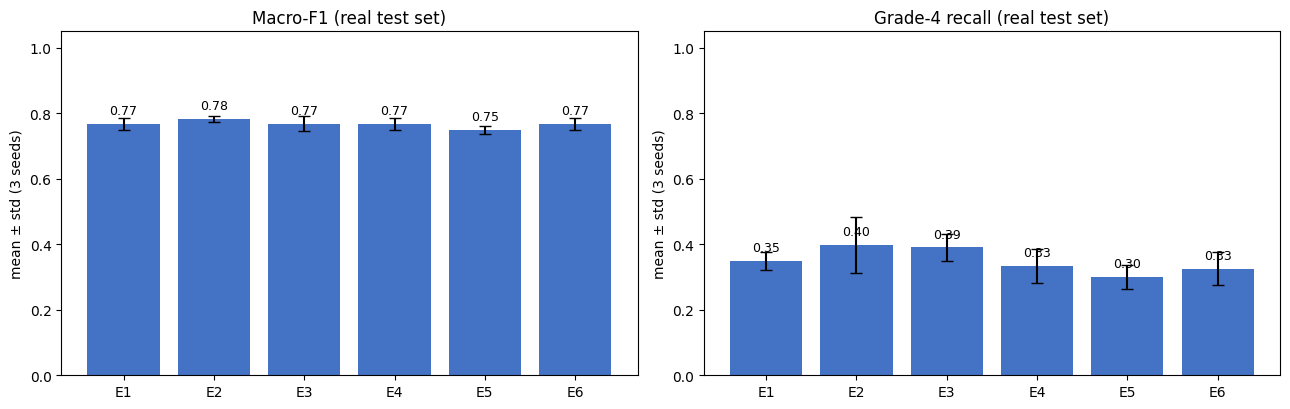

In [6]:
res = pd.read_csv(CSV)
res = res[res.ratio == 1.0]
cols = ['test_accuracy', 'test_macro_f1', 'test_qwk', 'test_recall_g0', 'test_recall_g2', 'test_recall_g4']
agg = res.groupby('exp')[cols].agg(['mean', 'std'])
table = pd.DataFrame({c.replace('test_', ''): agg[c]['mean'].map('{:.3f}'.format) + ' ± '
                      + agg[c]['std'].map('{:.3f}'.format) for c in cols})
table.insert(0, 'setting', [EXPERIMENTS[e] for e in table.index])
table.to_csv(f'{RES}/classifier_summary.csv')
print(table.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, c, title in zip(axes, ['test_macro_f1', 'test_recall_g4'], ['Macro-F1 (real test set)', 'Grade-4 recall (real test set)']):
    ax.bar(agg.index, agg[c]['mean'], yerr=agg[c]['std'], capsize=4, color='#4472c4')
    for i, v in enumerate(agg[c]['mean']):
        ax.text(i, v + 0.03, f'{v:.2f}', ha='center', fontsize=9)
    ax.set_ylim(0, 1.05); ax.set_title(title); ax.set_ylabel('mean ± std (3 seeds)')
plt.tight_layout(); plt.savefig(f'{RES}/classifier_results.png', dpi=150); plt.show()

skip E5 seed 0 ratio 0.5 (already done)
skip E5 seed 1 ratio 0.5 (already done)
skip E5 seed 2 ratio 0.5 (already done)
skip E5 seed 0 ratio 2.0 (already done)
skip E5 seed 1 ratio 2.0 (already done)
skip E5 seed 2 ratio 2.0 (already done)
      test_macro_f1        test_recall_g4       
               mean    std           mean    std
ratio                                           
0.0           0.768  0.018          0.350  0.028
0.5           0.724  0.017          0.293  0.073
1.0           0.749  0.012          0.301  0.037
2.0           0.744  0.013          0.276  0.037


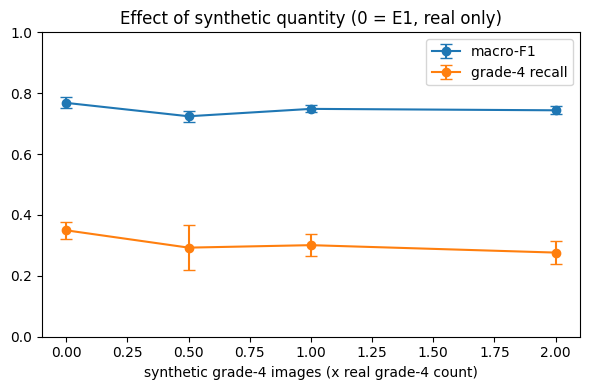

In [7]:
run_all([('E5', s, r) for r in (0.5, 2.0) for s in (0, 1, 2)])
res_all = pd.read_csv(CSV)
abl = res_all[res_all.exp == 'E5'].groupby('ratio')[['test_macro_f1', 'test_recall_g4']].agg(['mean', 'std'])
abl.loc[0.0] = res_all[res_all.exp == 'E1'][['test_macro_f1', 'test_recall_g4']].agg(['mean', 'std']).T.stack()
abl = abl.sort_index(); print(abl.round(3))
plt.figure(figsize=(6, 4))
for c, lab in [('test_macro_f1', 'macro-F1'), ('test_recall_g4', 'grade-4 recall')]:
    plt.errorbar(abl.index, abl[c]['mean'], yerr=abl[c]['std'], marker='o', capsize=4, label=lab)
plt.xlabel('synthetic grade-4 images (x real grade-4 count)'); plt.ylim(0, 1); plt.legend()
plt.title('Effect of synthetic quantity (0 = E1, real only)')
plt.tight_layout(); plt.savefig(f'{RES}/ablation_synthetic_quantity.png', dpi=150); plt.show()

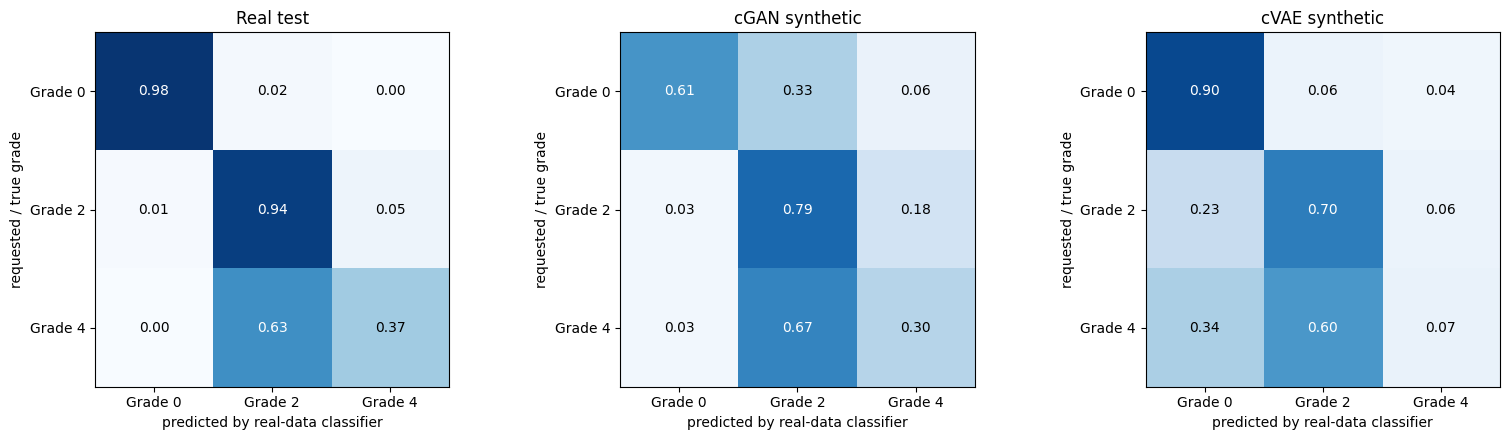

        source  overall_accuracy  acc_Grade 0  acc_Grade 2  acc_Grade 4
     Real test             0.910        0.977        0.945        0.366
cGAN synthetic             0.564        0.611        0.785        0.297
cVAE synthetic             0.558        0.903        0.703        0.067


In [8]:
judge = Classifier().to(device)
judge.load_state_dict(torch.load(JUDGE, map_location=device))
sources = [('Real test', Xte, Yte),
           ('cGAN synthetic', SYN['cgan'][0]['images'], SYN['cgan'][0]['labels']),
           ('cVAE synthetic', SYN['cvae'][0]['images'], SYN['cvae'][0]['labels'])]
rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, x, y) in zip(axes, sources):
    p = predict(judge, x)
    cm = confusion_matrix(y, p, labels=range(NUM_CLASSES), normalize='true')
    rows.append({'source': name, 'overall_accuracy': (p == y).mean(),
                 **{f'acc_{CLASS_NAMES[k]}': cm[k, k] for k in range(NUM_CLASSES)}})
    ax.imshow(cm, vmin=0, vmax=1, cmap='Blues')
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', color='white' if cm[i, j] > 0.5 else 'black')
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel('predicted by real-data classifier'); ax.set_ylabel('requested / true grade'); ax.set_title(name)
plt.tight_layout(); plt.savefig(f'{RES}/class_consistency.png', dpi=150); plt.show()
consistency = pd.DataFrame(rows).round(3)
consistency.to_csv(f'{RES}/class_consistency.csv', index=False); print(consistency.to_string(index=False))

In [9]:
from torchmetrics.image.fid import FrechetInceptionDistance
from torchmetrics.image.kid import KernelInceptionDistance
from torchmetrics.image.lpip import LearnedPerceptualImagePatchSimilarity

HOLD = np.isin(split, ['val', 'test'])
Xho, Yho = IMAGES[HOLD], LABELS[HOLD]          # real images never used for training

@torch.no_grad()
def fid_kid(real, fake):
    fid = FrechetInceptionDistance(feature=2048).to(device)
    kid = KernelInceptionDistance(subset_size=min(100, len(real), len(fake))).to(device)
    for x, is_real in ((real, True), (fake, False)):
        for s in range(0, len(x), 200):
            b = torch.from_numpy(x[s:s + 200]).permute(0, 3, 1, 2).to(device)   # uint8
            fid.update(b, real=is_real); kid.update(b, real=is_real)
    k_mean, k_std = kid.compute()
    return fid.compute().item(), k_mean.item(), k_std.item()

@torch.no_grad()
def mean_pairwise_lpips(x, n_pairs=500, seed=0):
    lp = LearnedPerceptualImagePatchSimilarity(net_type='alex', normalize=True).to(device)
    rng = np.random.default_rng(seed)
    i, j = rng.integers(len(x), size=n_pairs), rng.integers(len(x), size=n_pairs)
    i, j = i[i != j], j[i != j]
    for s in range(0, len(i), 100):
        lp.update(to_tensor(x[i[s:s + 100]]), to_tensor(x[j[s:s + 100]]))
    return lp.compute().item()

sources = {'Real held-out (reference)': (Xho, Yho),
           'cGAN': (SYN['cgan'][0]['images'], SYN['cgan'][0]['labels']),
           'cVAE': (SYN['cvae'][0]['images'], SYN['cvae'][0]['labels'])}
rows = []
for name, (x, y) in sources.items():
    for k in [None, 0, 1, 2]:
        r = Xtr if k is None else Xtr[Ytr == k]               # reference = real TRAIN images
        f = x if k is None else x[y == k]
        fid, km, ks = fid_kid(r, f)
        rows.append({'source': name, 'grade': 'all' if k is None else CLASS_NAMES[k],
                     'n_ref': len(r), 'n_eval': len(f), 'FID': round(fid, 1),
                     'KID_x1000': f'{km * 1000:.1f} ± {ks * 1000:.1f}',
                     'LPIPS_diversity': round(mean_pairwise_lpips(f), 3)})
        print(rows[-1])
fidelity = pd.DataFrame(rows)
fidelity.to_csv(f'{RES}/fidelity_diversity.csv', index=False)
print(fidelity.to_string(index=False))

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:02<00:00, 34.7MB/s]
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 173MB/s]


{'source': 'Real held-out (reference)', 'grade': 'all', 'n_ref': 2169, 'n_eval': 853, 'FID': 9.6, 'KID_x1000': '0.2 ± 1.2', 'LPIPS_diversity': 0.209}
{'source': 'Real held-out (reference)', 'grade': 'Grade 0', 'n_ref': 1263, 'n_eval': 526, 'FID': 11.8, 'KID_x1000': '-0.1 ± 1.0', 'LPIPS_diversity': 0.208}
{'source': 'Real held-out (reference)', 'grade': 'Grade 2', 'n_ref': 699, 'n_eval': 247, 'FID': 24.4, 'KID_x1000': '0.1 ± 0.7', 'LPIPS_diversity': 0.188}
{'source': 'Real held-out (reference)', 'grade': 'Grade 4', 'n_ref': 207, 'n_eval': 80, 'FID': 49.8, 'KID_x1000': '0.3 ± 0.8', 'LPIPS_diversity': 0.194}
{'source': 'cGAN', 'grade': 'all', 'n_ref': 2169, 'n_eval': 3000, 'FID': 63.7, 'KID_x1000': '55.4 ± 5.5', 'LPIPS_diversity': 0.219}
{'source': 'cGAN', 'grade': 'Grade 0', 'n_ref': 1263, 'n_eval': 1000, 'FID': 72.4, 'KID_x1000': '55.5 ± 4.1', 'LPIPS_diversity': 0.251}
{'source': 'cGAN', 'grade': 'Grade 2', 'n_ref': 699, 'n_eval': 1000, 'FID': 69.3, 'KID_x1000': '56.2 ± 3.7', 'LPIPS_div

                   source  median_NN_RMSE  p5_NN_RMSE  min_NN_RMSE  frac_closer_than_real_p5
Real held-out (reference)          0.0449      0.0293       0.0211                    0.0504
                     cGAN          0.0555      0.0389       0.0268                    0.0013
                     cVAE          0.0503      0.0343       0.0247                    0.0107


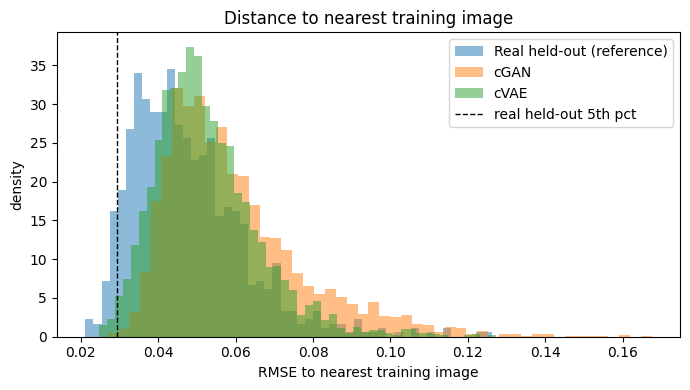

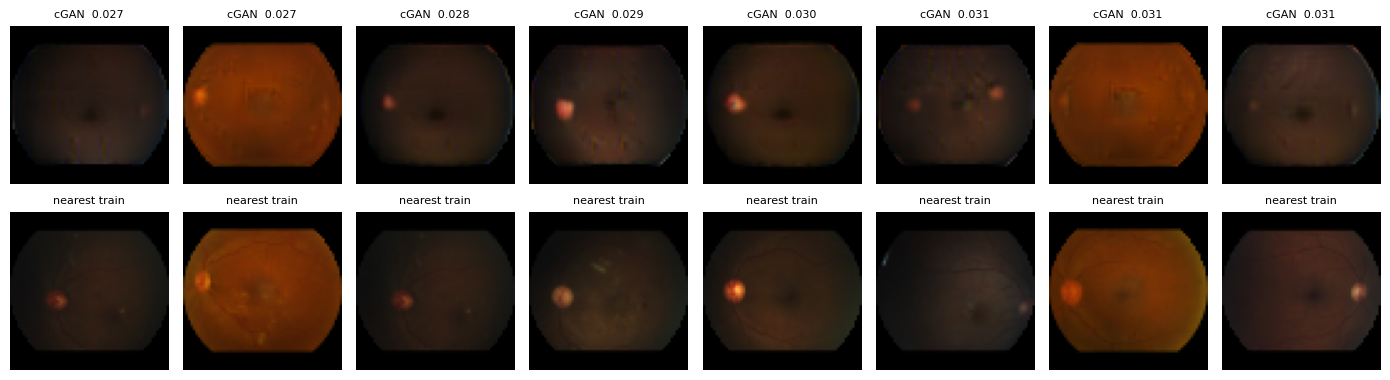

In [10]:
@torch.no_grad()
def nearest_train(query):
    """Pixel RMSE from each query image to its nearest TRAINING image."""
    R = torch.from_numpy(Xtr).to(device).float().flatten(1) / 255
    dist, idx = [], []
    for s in range(0, len(query), 500):
        Q = torch.from_numpy(query[s:s + 500]).to(device).float().flatten(1) / 255
        m, i = torch.cdist(Q, R).min(1)
        dist.append((m / R.size(1) ** 0.5).cpu()); idx.append(i.cpu())
    return torch.cat(dist).numpy(), torch.cat(idx).numpy()

nn_res = {name: nearest_train(x) for name, (x, _) in sources.items()}
ref_p5 = np.percentile(nn_res['Real held-out (reference)'][0], 5)
rows = []
for name, (dist, _) in nn_res.items():
    rows.append({'source': name, 'median_NN_RMSE': np.median(dist), 'p5_NN_RMSE': np.percentile(dist, 5),
                 'min_NN_RMSE': dist.min(),
                 'frac_closer_than_real_p5': (dist < ref_p5).mean()})
memo = pd.DataFrame(rows).round(4)
memo.to_csv(f'{RES}/memorisation.csv', index=False); print(memo.to_string(index=False))

plt.figure(figsize=(7, 4))
for name, (dist, _) in nn_res.items():
    plt.hist(dist, bins=50, alpha=0.5, density=True, label=name)
plt.axvline(ref_p5, color='k', ls='--', lw=1, label='real held-out 5th pct')
plt.xlabel('RMSE to nearest training image'); plt.ylabel('density'); plt.legend()
plt.title('Distance to nearest training image'); plt.tight_layout()
plt.savefig(f'{RES}/memorisation_hist.png', dpi=150); plt.show()

# the 8 cGAN images closest to a training image, with that training image
dist, idx = nn_res['cGAN']
order = np.argsort(dist)[:8]
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for k, o in enumerate(order):
    axes[0, k].imshow(sources['cGAN'][0][o]); axes[0, k].set_title(f'cGAN  {dist[o]:.3f}', fontsize=8)
    axes[1, k].imshow(Xtr[idx[o]]); axes[1, k].set_title('nearest train', fontsize=8)
    axes[0, k].axis('off'); axes[1, k].axis('off')
plt.tight_layout(); plt.savefig(f'{RES}/memorisation_closest_pairs.png', dpi=150); plt.show()

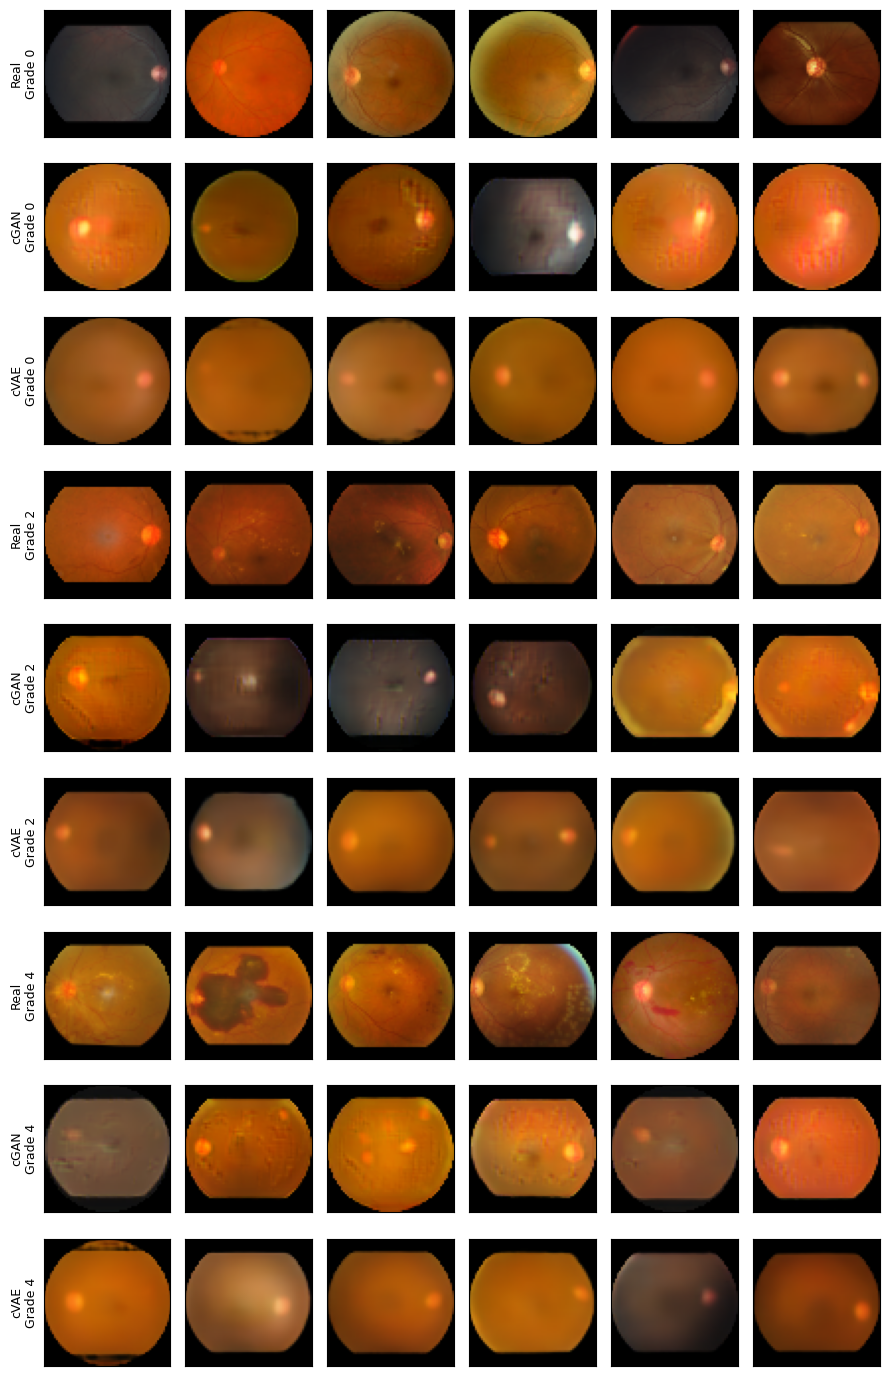

In [11]:
rng = np.random.default_rng(3)
rows = [('Real', Xtr, Ytr), ('cGAN', SYN['cgan'][0]['images'], SYN['cgan'][0]['labels']),
        ('cVAE', SYN['cvae'][0]['images'], SYN['cvae'][0]['labels'])]
fig, axes = plt.subplots(9, 6, figsize=(9, 14))
for k in range(NUM_CLASSES):
    for r, (name, x, y) in enumerate(rows):
        ids = rng.choice(np.where(y == k)[0], 6, replace=False)
        for j, i in enumerate(ids):
            ax = axes[3 * k + r, j]; ax.imshow(x[i]); ax.set_xticks([]); ax.set_yticks([])
        axes[3 * k + r, 0].set_ylabel(f'{name}\n{CLASS_NAMES[k]}', fontsize=9)
plt.tight_layout(); plt.savefig(f'{RES}/comparison_grid.png', dpi=150); plt.show()